# Assignment Task 2: Visualise Data Insights using Seaborn (15 marks)

### Import libraries and load data (1 mark)


In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("bidadari_resort_bookings.csv")
df.head()

,ID,Nationality,Age,DaysSinceCreation,arrival_date_year,arrival_date_month,AverageLeadTime,Revenue,OtherRevenue,BookingsCanceled,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
0,1.0,PRT,51.0,150.0,2016,July,45.0,371.0,105.3,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,PRT,NaN,1095.0,2016,July,61.0,280.0,53.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,FRA,60.0,1095.0,2016,July,93.0,240.0,60.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,6.0,JPN,54.0,1095.0,2016,July,58.0,230.0,24.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8.0,FRA,32.0,1095.0,2016,July,38.0,535.0,94.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


### Sub Task 1: Visualise Distribution of Revenue using Seaborn Histogram (1 mark)

Build a histogram of lodging revenue with Seaborn. Filter your data to rows where Revenue is less than 2000. 

<AxesSubplot:xlabel='Revenue', ylabel='Count'>

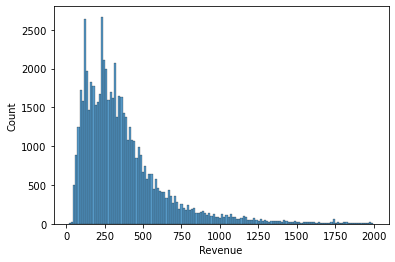

In [3]:
sns.histplot(data=df.Revenue[df.Revenue < 2000])

### Sub Task 2: Create a Bar Chart (2 marks)

Create a horizontal bar chart plotting the average room nights stayed for selected 5 nationalities by revenue ("DEU", "FRA", "PRT", "GBR", "ESP"). Change the color palette to "husl".

In [46]:
nations = ["DEU", "FRA", "PRT", "GBR", "ESP"]


nations5 = df[df['Nationality'].isin(nations)]


averagenights = nations5.groupby('Nationality')['RoomNights'].mean().reset_index()
averagenights

,Nationality,RoomNights
0,DEU,3.336588
1,ESP,2.763868
2,FRA,3.305606
3,GBR,3.171263
4,PRT,2.557056


In [55]:
totalrevenue = nations5.groupby('Nationality')['Revenue'].sum().reset_index()
# sortednations = nations5.sort_values(by=totalrevenue).reset_index()
totalrevenue

,Nationality,Revenue
0,DEU,3113382.55
1,ESP,1475909.33
2,FRA,3809315.59
3,GBR,2693123.61
4,PRT,2715008.72


In [61]:
revnights = totalrevenue.join(averagenights.set_index('Nationality'), on='Nationality')
sortednights = revnights.sort_values(by=['Revenue'])
sortednights

,Nationality,Revenue,RoomNights
1,ESP,1475909.33,2.763868
3,GBR,2693123.61,3.171263
4,PRT,2715008.72,2.557056
0,DEU,3113382.55,3.336588
2,FRA,3809315.59,3.305606


<AxesSubplot:xlabel='RoomNights', ylabel='Nationality'>

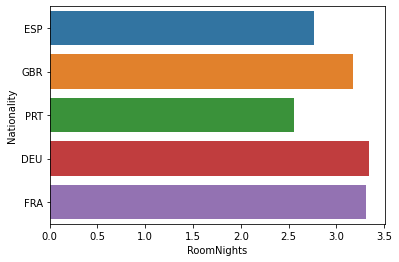

In [62]:
sns.barplot(x=sortednights.RoomNights, y=sortednights.Nationality, orient='h')

### Sub Task 3: Create a Box Plot (1 mark)

Create a single boxplot of Revenue for the selected 5 countries, where nightly revenue is less than 2000.


In [63]:
nations5.columns

Index(['ID', 'Nationality', 'Age', 'DaysSinceCreation', 'arrival_date_year',
       'arrival_date_month', 'AverageLeadTime', 'Revenue', 'OtherRevenue',
       'BookingsCanceled', 'BookingsNoShowed', 'BookingsCheckedIn',
       'PersonsNights', 'RoomNights', 'DaysSinceLastStay',
       'DaysSinceFirstStay', 'DistributionChannel', 'MarketSegment',
       'SRHighFloor', 'SRLowFloor', 'SRAccessibleRoom', 'SRMediumFloor',
       'SRBathtub', 'SRShower', 'SRCrib', 'SRKingSizeBed', 'SRTwinBed',
       'SRNearElevator', 'SRAwayFromElevator', 'SRNoAlcoholInMiniBar',
       'SRQuietRoom'],
      dtype='object')

In [68]:
nations5.shape

(36927, 31)

In [73]:
nations5[nations5.Nationality == 'DEU']

,ID,Nationality,Age,DaysSinceCreation,arrival_date_year,arrival_date_month,AverageLeadTime,Revenue,OtherRevenue,BookingsCanceled,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
21,37.0,DEU,30.0,1095.0,2016,July,13.0,210.00,73.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
89,167.0,DEU,60.0,1093.0,2016,July,72.0,464.00,290.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
97,182.0,DEU,67.0,1093.0,2016,July,46.0,114.00,28.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
115,214.0,DEU,53.0,1093.0,2016,July,75.0,687.65,196.50,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
185,335.0,DEU,30.0,1091.0,2016,July,29.0,300.24,256.36,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63165,83554.0,DEU,26.0,0.0,2016,December,107.0,584.00,54.50,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
63166,83555.0,DEU,59.0,0.0,2016,December,110.0,569.00,50.50,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
63167,83557.0,DEU,47.0,0.0,2016,December,249.0,406.30,231.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
63169,83561.0,DEU,48.0,0.0,2016,December,249.0,406.30,288.00,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [79]:
nations5.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 36927 entries, 0 to 63178
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    36927 non-null  float64
 1   Nationality           36927 non-null  object 
 2   Age                   34126 non-null  float64
 3   DaysSinceCreation     36927 non-null  float64
 4   arrival_date_year     36927 non-null  int64  
 5   arrival_date_month    36927 non-null  object 
 6   AverageLeadTime       36927 non-null  float64
 7   Revenue               36927 non-null  float64
 8   OtherRevenue          36927 non-null  float64
 9   BookingsCanceled      36927 non-null  float64
 10  BookingsNoShowed      36927 non-null  float64
 11  BookingsCheckedIn     36927 non-null  float64
 12  PersonsNights         36927 non-null  float64
 13  RoomNights            36927 non-null  float64
 14  DaysSinceLastStay     36927 non-null  float64
 15  DaysSinceFirstStay 

In [81]:
lessthan = nations5[nations5.Revenue < 2000.00].reset_index()
lessthan.shape

(36660, 32)

In [84]:
lessthan['Nationality'].dtypes

dtype('O')

<AxesSubplot:xlabel='Revenue'>

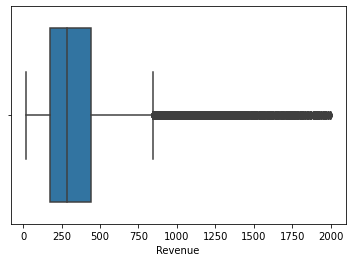

In [86]:
sns.boxplot(data=lessthan, x="Revenue")

### Sub Task 4: Create ViolinPlots ( 2 marks)

1. Create a chart that has one violinplot for each nationality. Look at these plots both without a filter and with  revenue filtered to less than 2000 and number of nights is less than 10 nights.
2. Create a violinplot for the age distribution for each of the selected 5 nationalities

In [99]:
df['RoomNights'].head()

0    5.0
1    5.0
2    5.0
3    2.0
4    5.0
Name: RoomNights, dtype: float64

In [107]:
lessthan2k = df['Revenue'] < 2000
nights10 = df['RoomNights'] < 10

countnations = df['Nationality'].value_counts().reset_index()
# countnations.head()

less = df[lessthan2k]['Nationality'].value_counts().reset_index()
nights = df[nights10]['Nationality'].value_counts().reset_index()

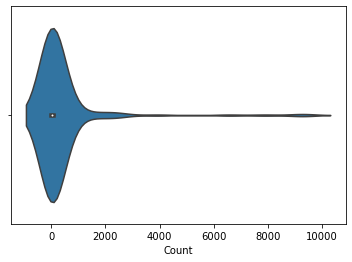

In [110]:
sns.violinplot(x=countnations["Nationality"])
plt.xlabel('Count')
plt.show()

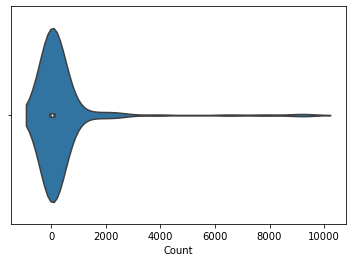

In [104]:
sns.violinplot(data=less, x="Nationality")
plt.xlabel('Count')
plt.show()

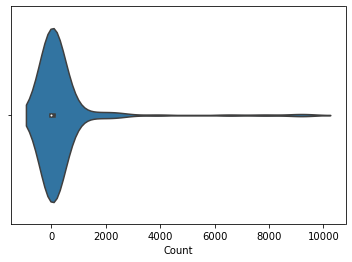

In [105]:
sns.violinplot(data=nights, x="Nationality")
plt.xlabel('Count')
plt.show()

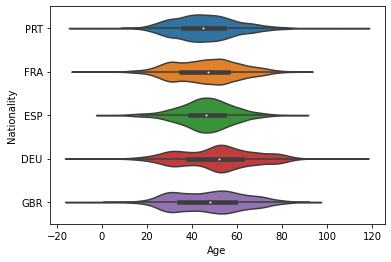

In [112]:
sns.violinplot(data=nations5, x="Age", y="Nationality")
plt.xlabel('Age')
plt.show()

### Sub Task 5: Linear Relationship Plots (2 marks)

1. Create a regression plot comparing Revenue as y and RoomNights as x for rows in 5 selected countries.
2. Modify the regresssion plot and use different colour line to represent the 5 nationalities. Which nationality appears to pay the most per night for customers with  revenue filtered is less than 2000 and number of nights is less than 10 nights ? Indicate your answer using Markdown cell.


<AxesSubplot:xlabel='Revenue', ylabel='RoomNights'>

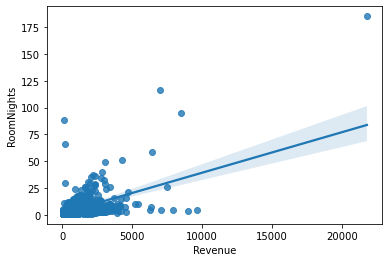

In [113]:
sns.regplot(data=nations5, x='Revenue', y='RoomNights')

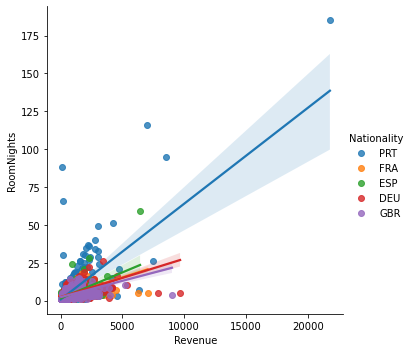

In [115]:
sns.lmplot(data=nations5, x='Revenue', y='RoomNights', hue='Nationality')

C:\Users\zoe\AppData\Local\Temp/ipykernel_17884/1079707913.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered = nations5[lessthan2k | nights10].reset_index()


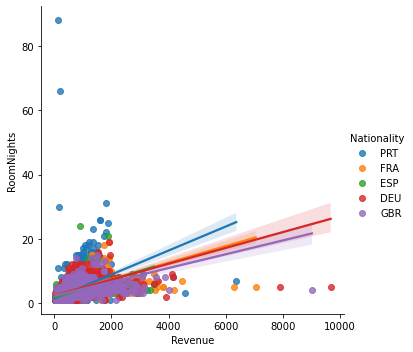

In [120]:
lessthan2k = df['Revenue'] < 2000
nights10 = df['RoomNights'] < 10

filtered = nations5[lessthan2k | nights10].reset_index()

sns.lmplot(data=filtered, x='Revenue', y='RoomNights', hue='Nationality')

After filtering, It is evident that DEU, Germany has the highest revenue while having a low number of nights occupied.

### Sub Task 6: Create a Pairplot (2 marks)

Create a pairplot with the columns: Age, Revenue, OtherRevenue, PersonsNights, RoomNights and DaysSinceLastStay

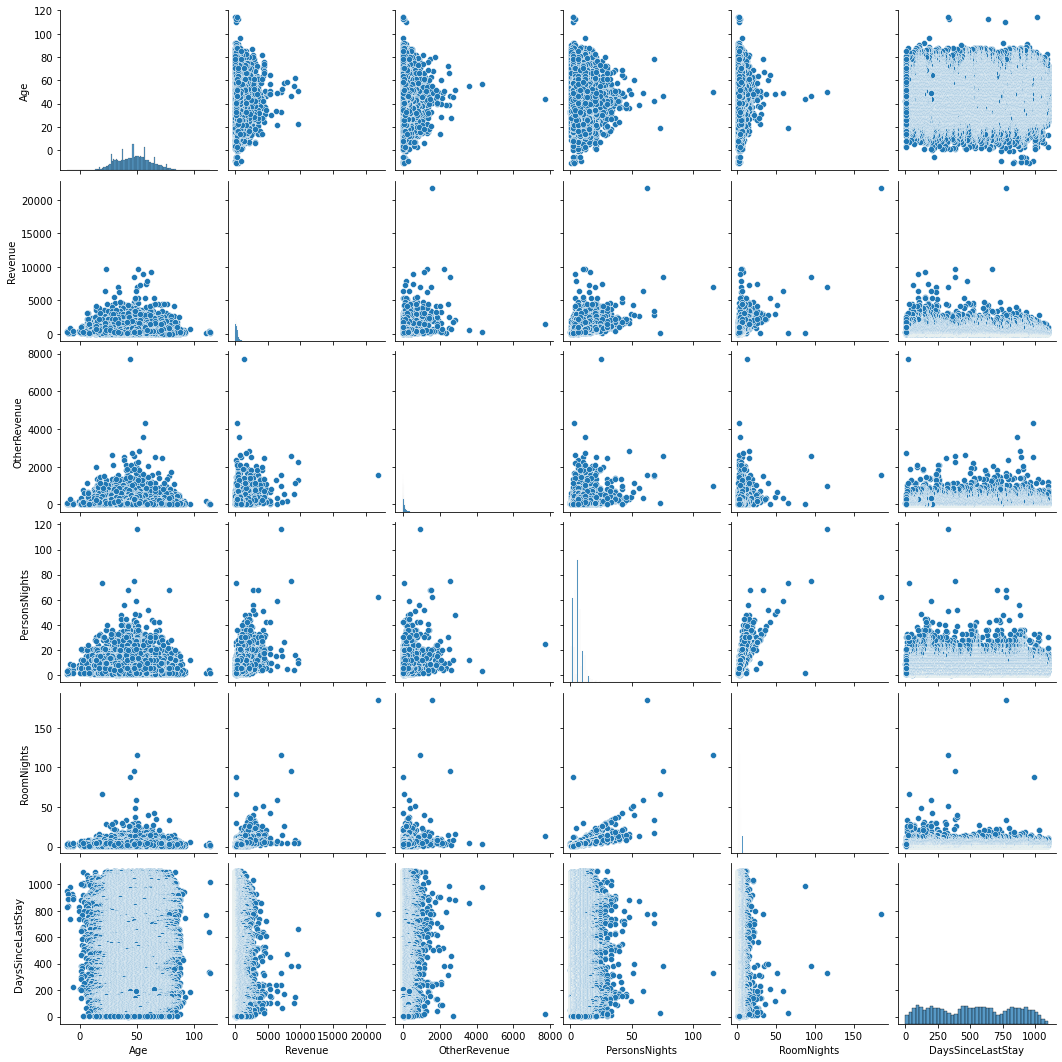

In [121]:
paircols = ['Age', 'Revenue', 'OtherRevenue', 'PersonsNights', 'RoomNights' , 'DaysSinceLastStay']
pairplot = df[paircols]

sns.pairplot(pairplot)

### Sub Task 7: Create Heatmap (2 marks)

1. Using the 5 selected countries DataFrame, create a heatmap of Nationality as rows and MarketSegment as columns with the mean value of Revenue in each cell.
2. Create a heatmap of the correlation matrix created when using the .corr() method on the transactions dataframe. Use the 'vlag' color palette.

<AxesSubplot:xlabel='MarketSegment', ylabel='Nationality'>

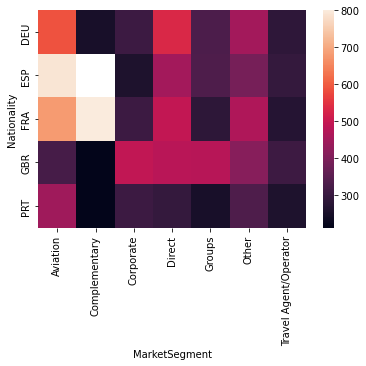

In [127]:
import numpy as np
maps = pd.pivot_table(nations5, index='Nationality', columns='MarketSegment', values='Revenue', aggfunc=np.mean)
sns.heatmap(maps)

C:\Users\zoe\AppData\Local\Temp/ipykernel_17884/563120864.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  matrix = df.corr()


<AxesSubplot:>

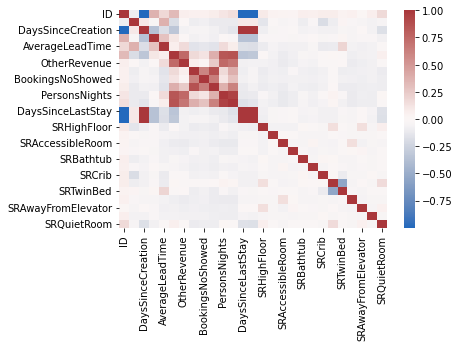

In [131]:
matrix = df.corr()
sns.heatmap(matrix.corr(), cmap = 'vlag')


### Sub Task 8: Conclusion (2 marks)

Summarise your data exploratory task in one or 2 paragraph(s)
